In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")

# TotalCharges: blank strings -> NaN -> 0 (these are tenure = 0 customers)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce").fillna(0)

# Target to 1/0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Merge "No internet service" / "No phone service" into "No"
cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
        "TechSupport", "StreamingTV", "StreamingMovies", "MultipleLines"]
df[cols] = df[cols].replace({"No internet service": "No", "No phone service": "No"})

df = df.drop(columns=["customerID"])

c:\Users\DEEPA\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.8.7' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
c:\Users\DEEPA\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.7' currently installed).
  from pandas.core import (


In [3]:
# Tenure bands
df["tenure_group"] = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                            labels=["0-12", "13-24", "25-48", "49-72"])

# Number of add-on services
service_cols = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_services"] = (df[service_cols] == "Yes").sum(axis=1)

# Average monthly spend vs. current monthly charge
df["avg_monthly"] = df["TotalCharges"] / df["tenure"].replace(0, np.nan)
df["avg_monthly"] = df["avg_monthly"].fillna(df["MonthlyCharges"])
df["charge_diff"] = df["MonthlyCharges"] - df["avg_monthly"]

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
cat_cols = X.select_dtypes(exclude=["int64", "float64"]).columns.tolist()

preprocess = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
])

In [5]:
df.corr(numeric_only=True)

,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Churn,num_services,avg_monthly,charge_diff
SeniorCitizen,1.000000,0.016567,0.220173,0.103006,0.150889,0.067493,0.217917,0.017651
tenure,0.016567,1.000000,0.247900,0.826178,-0.352229,0.494263,0.247234,-0.001771
MonthlyCharges,0.220173,0.247900,1.000000,0.651174,0.193356,0.724706,0.996244,0.005217
TotalCharges,0.103006,0.826178,0.651174,1.000000,-0.198324,0.744827,0.651025,-0.023124
Churn,0.150889,-0.352229,0.193356,-0.198324,1.000000,-0.087698,0.192531,0.002159
num_services,0.067493,0.494263,0.724706,0.744827,-0.087698,1.000000,0.722843,-0.006142
avg_monthly,0.217917,0.247234,0.996244,0.651025,0.192531,0.722843,1.000000,-0.081389
charge_diff,0.017651,-0.001771,0.005217,-0.023124,0.002159,-0.006142,-0.081389,1.000000


In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

pos_weight = (y_train == 0).sum() / (y_train == 1).sum()  # about 2.77

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, class_weight="balanced"),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", random_state=42, n_jobs=-1),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4,
        scale_pos_weight=pos_weight, eval_metric="logloss", random_state=42),
}

pipes = {}
for name, model in models.items():
    pipes[name] = Pipeline([("prep", preprocess), ("model", model)])
    pipes[name].fit(X_train, y_train)

In [7]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [8]:
from sklearn.metrics import (classification_report, roc_auc_score,
                             precision_score, recall_score, f1_score)

results = []
for name, pipe in pipes.items():
    pred = pipe.predict(X_test)
    proba = pipe.predict_proba(X_test)[:, 1]
    results.append({
        "Model": name,
        "Precision": precision_score(y_test, pred),
        "Recall": recall_score(y_test, pred),
        "F1": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })

print(pd.DataFrame(results).round(3))

                 Model  Precision  Recall     F1  ROC-AUC
0  Logistic Regression      0.498   0.791  0.612    0.842
1        Random Forest      0.564   0.650  0.604    0.827
2              XGBoost      0.516   0.781  0.621    0.837


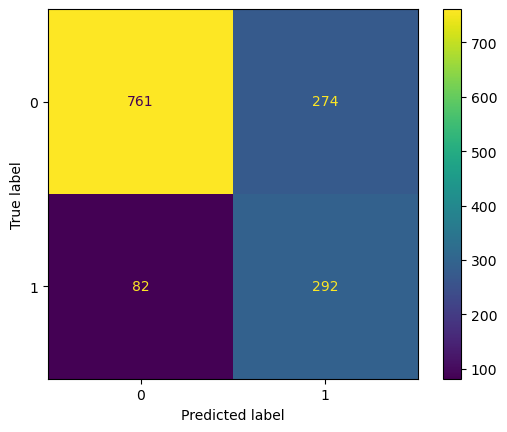

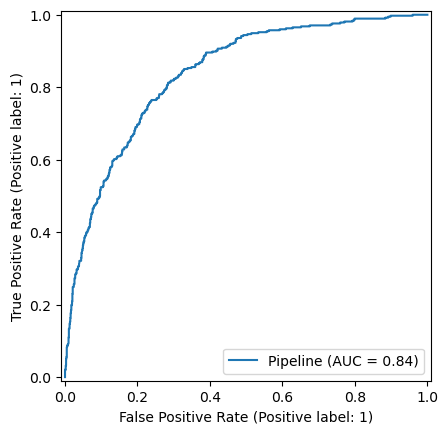

In [9]:
from sklearn.metrics import ConfusionMatrixDisplay, RocCurveDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_estimator(pipes["XGBoost"], X_test, y_test)
RocCurveDisplay.from_estimator(pipes["XGBoost"], X_test, y_test)
plt.show()

In [10]:
from sklearn.model_selection import StratifiedKFold, cross_val_score, RandomizedSearchCV

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(pipes["XGBoost"], X_train, y_train, cv=cv, scoring="roc_auc")
print(scores.mean(), scores.std())

param_dist = {
    "model__n_estimators": [200, 300, 500],
    "model__max_depth": [3, 4, 5, 6],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__subsample": [0.7, 0.8, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 1.0],
}
search = RandomizedSearchCV(pipes["XGBoost"], param_dist, n_iter=20,
                            scoring="recall", cv=cv, random_state=42, n_jobs=-1)
search.fit(X_train, y_train)
best = search.best_estimator_

0.8409893035941363 0.010819148066897908


In [11]:
proba = best.predict_proba(X_test)[:, 1]
for t in [0.3, 0.4, 0.5]:
    pred = (proba >= t).astype(int)
    print(t, precision_score(y_test, pred), recall_score(y_test, pred))

0.3 0.40022547914317924 0.9491978609625669
0.4 0.44638069705093836 0.8903743315508021
0.5 0.5083612040133779 0.8128342245989305


In [12]:
%pip install shap

Note: you may need to restart the kernel to use updated packages.


In [ ]:
%pip install --force-reinstall numpy==1.26.4 shap==0.49.1

In [ ]:
import sys
import numpy as np
import shap
import xgboost as xgb

print("Python:", sys.version)
print("NumPy:", np.__version__)
print("SHAP:", shap.__version__)
print("XGBoost:", xgb.__version__)
print("Model type:", type(best.named_steps["model"]))

Python: 3.12.7 | packaged by Anaconda, Inc. | (main, Oct  4 2024, 13:17:27) [MSC v.1929 64 bit (AMD64)]
NumPy: 1.26.4
SHAP: 0.49.1
XGBoost: 3.4.1
Model type: <class 'xgboost.sklearn.XGBClassifier'>


In [ ]:
import xgboost as xgb
import numpy as np

model = best.named_steps["model"]

dtest = xgb.DMatrix(X_test_t)

contributions = model.get_booster().predict(
    dtest,
    pred_contribs=True
)

feature_importance = np.abs(contributions[:, :-1]).mean(axis=0)

print("Feature importance calculated successfully")
print(feature_importance)

NameError: name 'X_test_t' is not defined

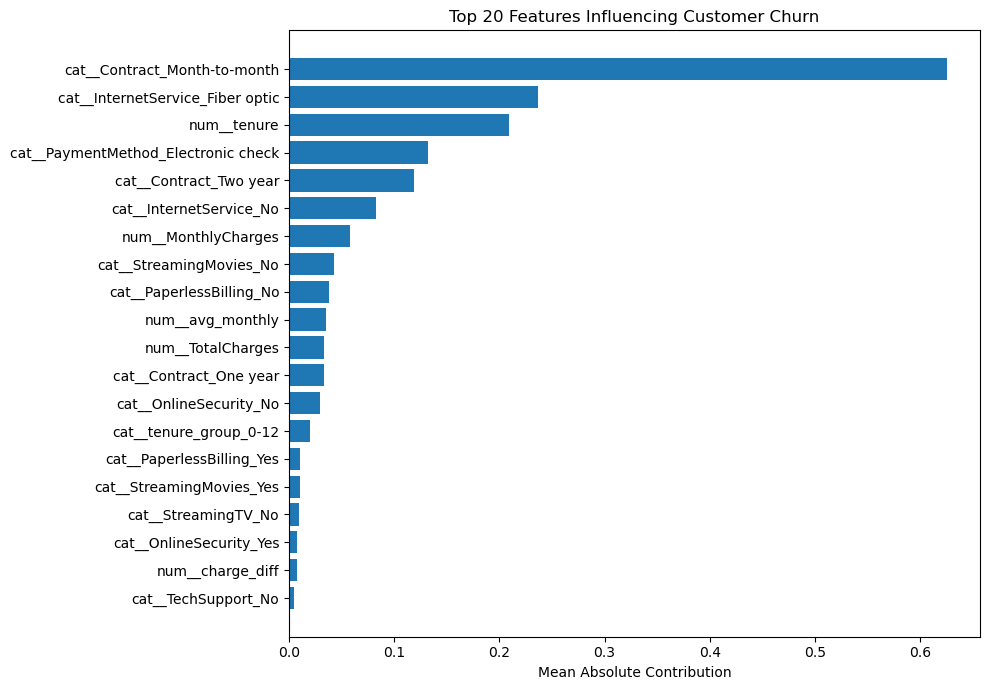

In [ ]:
import xgboost as xgb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

prep = best.named_steps["prep"]
model = best.named_steps["model"]

X_test_t = prep.transform(X_test)
feature_names = prep.get_feature_names_out()

# Convert to XGBoost's data format
dtest = xgb.DMatrix(X_test_t)

# Calculate feature contributions using XGBoost
contributions = model.get_booster().predict(
    dtest,
    pred_contribs=True
)

# The final column is the bias term, not a feature
contributions = contributions[:, :-1]

# Calculate global feature importance
importance = np.abs(contributions).mean(axis=0)

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Mean_Abs_Contribution": importance
}).sort_values("Mean_Abs_Contribution", ascending=False)

# Plot the top 20 features
top_features = importance_df.head(20).sort_values(
    "Mean_Abs_Contribution"
)

plt.figure(figsize=(10, 7))
plt.barh(
    top_features["Feature"],
    top_features["Mean_Abs_Contribution"]
)
plt.xlabel("Mean Absolute Contribution")
plt.title("Top 20 Features Influencing Customer Churn")
plt.tight_layout()
plt.show()

In [ ]:
test_df = X_test.copy()
test_df["churn_prob"] = proba
test_df["actual"] = y_test.values

top20 = test_df.sort_values("churn_prob", ascending=False).head(int(0.2 * len(test_df)))

# Assumptions (state these clearly in your README)
customer_value = 1000      # avg lifetime value
offer_cost = 50            # cost per retention offer
success_rate = 0.30        # share of churners who accept the offer

churners_caught = top20["actual"].sum()
saved = churners_caught * success_rate * customer_value
cost = len(top20) * offer_cost
print(f"Churners in top 20%: {churners_caught}")
print(f"Net benefit: {saved - cost:,.0f}")

Churners in top 20%: 184
Net benefit: 41,150


In [ ]:
import joblib
joblib.dump(best, "churn_model.pkl")

NameError: name 'best' is not defined